# Week 6: Davis Southern Club Women

**Question:** What can we conclude about the relationships between (1) the women and (2) the social events?

The data: 18 women and 14 social events from a 1941 study. Each line in the network means "this woman attended this event". Women connect only to events, never directly to each other (a *bipartite* network).

## Step 1: Load the data

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

# This is the same dataset as davis.dat, built into NetworkX
G = nx.davis_southern_women_graph()

# Split the nodes into two lists: women and events
women = [n for n, d in G.nodes(data=True) if d["bipartite"] == 0]
events = [n for n, d in G.nodes(data=True) if d["bipartite"] == 1]

print("Women:", len(women))
print("Events:", len(events))
print("Attendances (lines in the graph):", G.number_of_edges())

Women: 18
Events: 14
Attendances (lines in the graph): 89


## Step 2: Draw the network
Orange circles are women, green squares are events. A line means the woman attended that event.

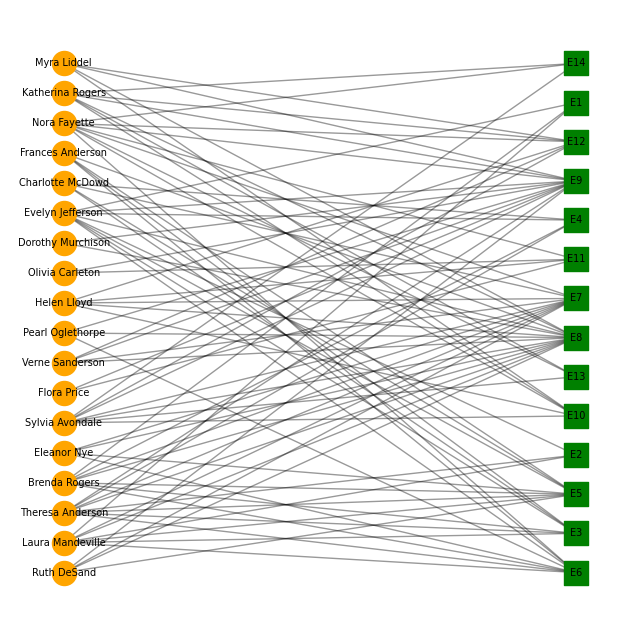

In [2]:
pos = nx.bipartite_layout(G, women)   # women on one side, events on the other

plt.figure(figsize=(8, 8))
nx.draw_networkx_nodes(G, pos, nodelist=women, node_color="orange")
nx.draw_networkx_nodes(G, pos, nodelist=events, node_color="green", node_shape="s")
nx.draw_networkx_edges(G, pos, alpha=0.4)
nx.draw_networkx_labels(G, pos, font_size=7)
plt.axis("off")
plt.show()

## Step 3: Who attends the most? Which events are most popular?
The *degree* of a node is the number of lines connected to it.

In [3]:
# Number of events each woman attended (highest first)
women_degree = sorted(G.degree(women), key=lambda x: x[1], reverse=True)
print("Events attended per woman:")
for name, count in women_degree:
    print(" ", name, count)

# Number of women at each event (highest first)
events_degree = sorted(G.degree(events), key=lambda x: x[1], reverse=True)
print("\nWomen attending each event:")
for name, count in events_degree:
    print(" ", name, count)

Events attended per woman:
  Evelyn Jefferson 8
  Theresa Anderson 8
  Nora Fayette 8
  Laura Mandeville 7
  Brenda Rogers 7
  Sylvia Avondale 7
  Katherina Rogers 6
  Helen Lloyd 5
  Charlotte McDowd 4
  Frances Anderson 4
  Eleanor Nye 4
  Ruth DeSand 4
  Verne Sanderson 4
  Myra Liddel 4
  Pearl Oglethorpe 3
  Dorothy Murchison 2
  Olivia Carleton 2
  Flora Price 2

Women attending each event:
  E8 14
  E9 12
  E7 10
  E5 8
  E6 8
  E3 6
  E12 6
  E10 5
  E4 4
  E11 4
  E1 3
  E2 3
  E13 3
  E14 3


## Step 4: Which women are connected to each other?
We link two women if they attended the same event. The number on each link (the *weight*) is how many events they attended together.

In [4]:
from networkx.algorithms import bipartite

W = bipartite.weighted_projected_graph(G, women)

print("Links between women:", W.number_of_edges())
print("Possible links:", 18 * 17 // 2)

# The 5 pairs of women who attended the most events together
top_pairs = sorted(W.edges(data="weight"), key=lambda x: x[2], reverse=True)[:5]
for a, b, w in top_pairs:
    print(a, "&", b, "->", w, "events together")

Links between women: 139
Possible links: 153
Evelyn Jefferson & Theresa Anderson -> 7 events together
Evelyn Jefferson & Brenda Rogers -> 6 events together
Evelyn Jefferson & Laura Mandeville -> 6 events together
Laura Mandeville & Theresa Anderson -> 6 events together
Laura Mandeville & Brenda Rogers -> 6 events together


Almost every pair of women shares at least one event, so "connected or not" tells us little. The weights are what matter. Next, we look for groups of women who attend the same events.

In [5]:
groups = nx.community.greedy_modularity_communities(W, weight="weight")

for i, group in enumerate(groups, 1):
    print("Group", i, "(", len(group), "women ):", sorted(group))

Group 1 ( 10 women ): ['Dorothy Murchison', 'Flora Price', 'Helen Lloyd', 'Katherina Rogers', 'Myra Liddel', 'Nora Fayette', 'Olivia Carleton', 'Pearl Oglethorpe', 'Sylvia Avondale', 'Verne Sanderson']
Group 2 ( 8 women ): ['Brenda Rogers', 'Charlotte McDowd', 'Eleanor Nye', 'Evelyn Jefferson', 'Frances Anderson', 'Laura Mandeville', 'Ruth DeSand', 'Theresa Anderson']


## Step 5: Do the two groups attend different events?
For each event, count how many women from group 1 and from group 2 came.

In [6]:
group1 = groups[0]
group2 = groups[1]

for event in events:
    attendees = list(G.neighbors(event))
    from_g1 = len([w for w in attendees if w in group1])
    from_g2 = len([w for w in attendees if w in group2])
    print(event, "| group 1:", from_g1, "| group 2:", from_g2)

E1 | group 1: 0 | group 2: 3
E2 | group 1: 0 | group 2: 3
E3 | group 1: 0 | group 2: 6
E4 | group 1: 0 | group 2: 4
E5 | group 1: 0 | group 2: 8
E6 | group 1: 2 | group 2: 6
E7 | group 1: 4 | group 2: 6
E8 | group 1: 7 | group 2: 7
E9 | group 1: 9 | group 2: 3
E10 | group 1: 5 | group 2: 0
E11 | group 1: 4 | group 2: 0
E12 | group 1: 6 | group 2: 0
E13 | group 1: 3 | group 2: 0
E14 | group 1: 3 | group 2: 0


## Conclusions

**Women.** The women are not one uniform club. They split into two groups (10 and 8 women), and women within a group attend many of the same events. The two groups match the two cliques described in the original 1941 study. Participation is also unequal: some women attend 8 of the 14 events, while others attend only 2 or 3.

**Events.** Most events are attended by only one of the two groups. Events E1-E5 are attended only by the smaller group of women, and E10-E14 only by the larger group. A few events (E6-E9) are mixed. E8 is the most popular (14 of 18 women, 7 from each group), and E9 is second (12 women). These mixed events are where the two groups meet, and they connect the whole network.

**Why it matters.** The groups exist because of which events women choose to attend, and events can be grouped by who attends them. Looking only at the women, almost everyone is linked to everyone, so the group structure only appears when we use the link weights.

**Limitations.** The dataset is small (18 women, 14 events) and records only attendance, not how close the women actually were.